# 🌪️ Saudi Arabia NWP: Data Representation & Spatiotemporal Exploration
### *Extended-Range Sand & Dust Storm Forecasting Platform*
**Dataset Target:** `notebooks/data/sandstorm_final_dataset_with_targets.csv`  
**Provider:** Copernicus Atmospheric Monitoring Service (CAMS) / ECMWF NWP  
**Domain:** Kingdom of Saudi Arabia (Riyadh Urban Receptor & 5 Major Desert Basins)  
**Temporal Coverage:** 2022 to 2026 (Hourly Operational Forecasts & Target Horizons)


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Publication Aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9

print("✅ Scientific computing and visualisation libraries successfully loaded!")


✅ Scientific computing and visualisation libraries successfully loaded!


---
## 1.0 Dataset Ingestion & Spatial Monitoring Network Overview
The dataset contains synchronized hourly numerical weather prediction (NWP) dust products across **6 strategically selected geographic sites** across Saudi Arabia:
1. **Ad-Dahna Desert (`ad_dahna`)** – Major sand dune corridor northeast of Riyadh (Source)
2. **Al-Thumamah (`al_thumamah`)** – Northern desert boundary buffer (Transport zone)
3. **Nafud Al-Thuwairat (`nafud_al_thuwairat`)** – Active northern sand sea (Source)
4. **Riyadh Center (`riyadh_center`)** – Primary urban receptor and population center ($24.71^\circ\text{N}, 46.67^\circ\text{E}$)
5. **Rub' al Khali (`rub_al_khali`)** – The Empty Quarter, world's largest contiguous sand desert (Dominant Source)
6. **Tuwayq Escarpment (`tuwayq_escarpment`)** – Mountain ridge influencing aerodynamic channeling

Each site includes 5 CAMS NWP parameters:
- `pm10_ugm3` ($\mu	ext{g}/	ext{m}^3$)
- `pm2_5_ugm3` ($\mu	ext{g}/	ext{m}^3$)
- `dust_surface_ugm3` ($\mu	ext{g}/	ext{m}^3$)
- `dust_aod_550nm` (dimensionless optical depth)
- `uv_index` (surface radiative index)


In [2]:
# Resolve path reliably whether run from root or notebooks/
data_candidates = [
    Path("notebooks/data/sandstorm_final_dataset_with_targets.csv"),
    Path("data/sandstorm_final_dataset_with_targets.csv"),
    Path("../data/sandstorm_final_dataset_with_targets.csv")
]
data_path = next(p for p in data_candidates if p.exists())

df = pd.read_csv(data_path)
df['time'] = pd.to_datetime(df['time'])

print("=" * 75)
print("🌍 SAUDI NWP DUST FORECAST DATASET - INGESTION SUMMARY")
print("=" * 75)
print(f"File Path:        {data_path}")
print(f"Total Rows:       {df.shape[0]:,} hourly observations")
print(f"Total Columns:    {df.shape[1]}")
print(f"Date Range:       {df['time'].min()} → {df['time'].max()}")
print(f"Years Covered:    {df['year'].unique().tolist()}")
print("=" * 75)
df.head(3)


🌍 SAUDI NWP DUST FORECAST DATASET - INGESTION SUMMARY
File Path:        notebooks\data\sandstorm_final_dataset_with_targets.csv
Total Rows:       37,200 hourly observations
Total Columns:    41
Date Range:       2022-08-04 00:00:00 → 2026-10-31 23:00:00
Years Covered:    [2022, 2023, 2024, 2025, 2026]


,time,year,month,day,hour,ad_dahna__cams_pm10_ugm3,ad_dahna__cams_pm2_5_ugm3,ad_dahna__cams_dust_surface_ugm3,ad_dahna__cams_dust_aod_550nm,ad_dahna__cams_uv_index,...,tuwayq_escarpment__cams_pm2_5_ugm3,tuwayq_escarpment__cams_dust_surface_ugm3,tuwayq_escarpment__cams_dust_aod_550nm,tuwayq_escarpment__cams_uv_index,target_pm10_1d,target_event_1d,target_pm10_3d,target_event_3d,target_pm10_7d,target_event_7d
0,2022-08-04 00:00:00,2022,8,4,0,60.8,30.0,55.0,0.47,0.0,...,21.4,99.0,0.47,0.0,54.0,0.0,78.0,0.0,393.9,0.0
1,2022-08-04 01:00:00,2022,8,4,1,58.2,29.3,51.0,0.46,0.0,...,21.7,90.0,0.47,0.0,55.5,0.0,92.2,0.0,354.8,0.0
2,2022-08-04 02:00:00,2022,8,4,2,55.1,28.1,45.0,0.46,0.0,...,21.5,78.0,0.48,0.0,57.7,0.0,135.0,0.0,357.6,0.0


---
## 2.0 Multi-Station Statistical Summary
We compute parametric and non-parametric statistical metrics for surface particulate matter ($PM_{10}$ and $PM_{2.5}$), surface dust concentration, and aerosol optical depth ($AOD_{550}$) across all monitoring stations.


In [3]:
stations = [
    ('Ad-Dahna Desert', 'ad_dahna'),
    ('Al-Thumamah Park', 'al_thumamah'),
    ('Nafud Al-Thuwairat', 'nafud_al_thuwairat'),
    ('Riyadh Urban Center', 'riyadh_center'),
    ('Rub al Khali (Empty Quarter)', 'rub_al_khali'),
    ('Tuwayq Escarpment', 'tuwayq_escarpment')
]

summary_rows = []
for station_name, prefix in stations:
    pm10_col = f"{prefix}__cams_pm10_ugm3"
    pm25_col = f"{prefix}__cams_pm2_5_ugm3"
    dust_col = f"{prefix}__cams_dust_surface_ugm3"
    aod_col  = f"{prefix}__cams_dust_aod_550nm"
    
    summary_rows.append({
        'Station': station_name,
        'Mean PM10 (μg/m³)': df[pm10_col].mean(),
        'Max PM10 (μg/m³)': df[pm10_col].max(),
        'P95 PM10 (μg/m³)': df[pm10_col].quantile(0.95),
        'Mean PM2.5 (μg/m³)': df[pm25_col].mean(),
        'Mean Dust Surface': df[dust_col].mean(),
        'Mean AOD (550nm)': df[aod_col].mean(),
        'Max AOD': df[aod_col].max()
    })

df_summary = pd.DataFrame(summary_rows).round(2)
print("📊 MULTI-STATION CAMS NWP DESCRIPTIVE STATISTICS:")
display(df_summary)


📊 MULTI-STATION CAMS NWP DESCRIPTIVE STATISTICS:


,Station,Mean PM10 (μg/m³),Max PM10 (μg/m³),P95 PM10 (μg/m³),Mean PM2.5 (μg/m³),Mean Dust Surface,Mean AOD (550nm),Max AOD
0,Ad-Dahna Desert,199.75,1922.2,551.3,33.22,380.09,0.44,1.99
1,Al-Thumamah Park,186.88,1486.4,497.3,31.69,357.90,0.42,2.28
2,Nafud Al-Thuwairat,174.17,1944.6,474.0,29.92,336.86,0.39,1.94
3,Riyadh Urban Center,675.19,3270.8,2436.3,78.95,1286.74,0.51,2.28
4,Rub al Khali (Empty Quarter),98.03,1799.3,289.6,23.21,164.13,0.39,2.21
5,Tuwayq Escarpment,167.20,1519.9,465.7,30.99,316.59,0.41,2.37


---
## 3.0 Regional Dust Gradient: Desert Sources vs. Riyadh Urban Receptor
Dust storms in Riyadh are primarily advected from surrounding high-emission desert basins. We analyze the contrast between the upstream sources (Rub' al Khali & Ad-Dahna) and Riyadh Center.


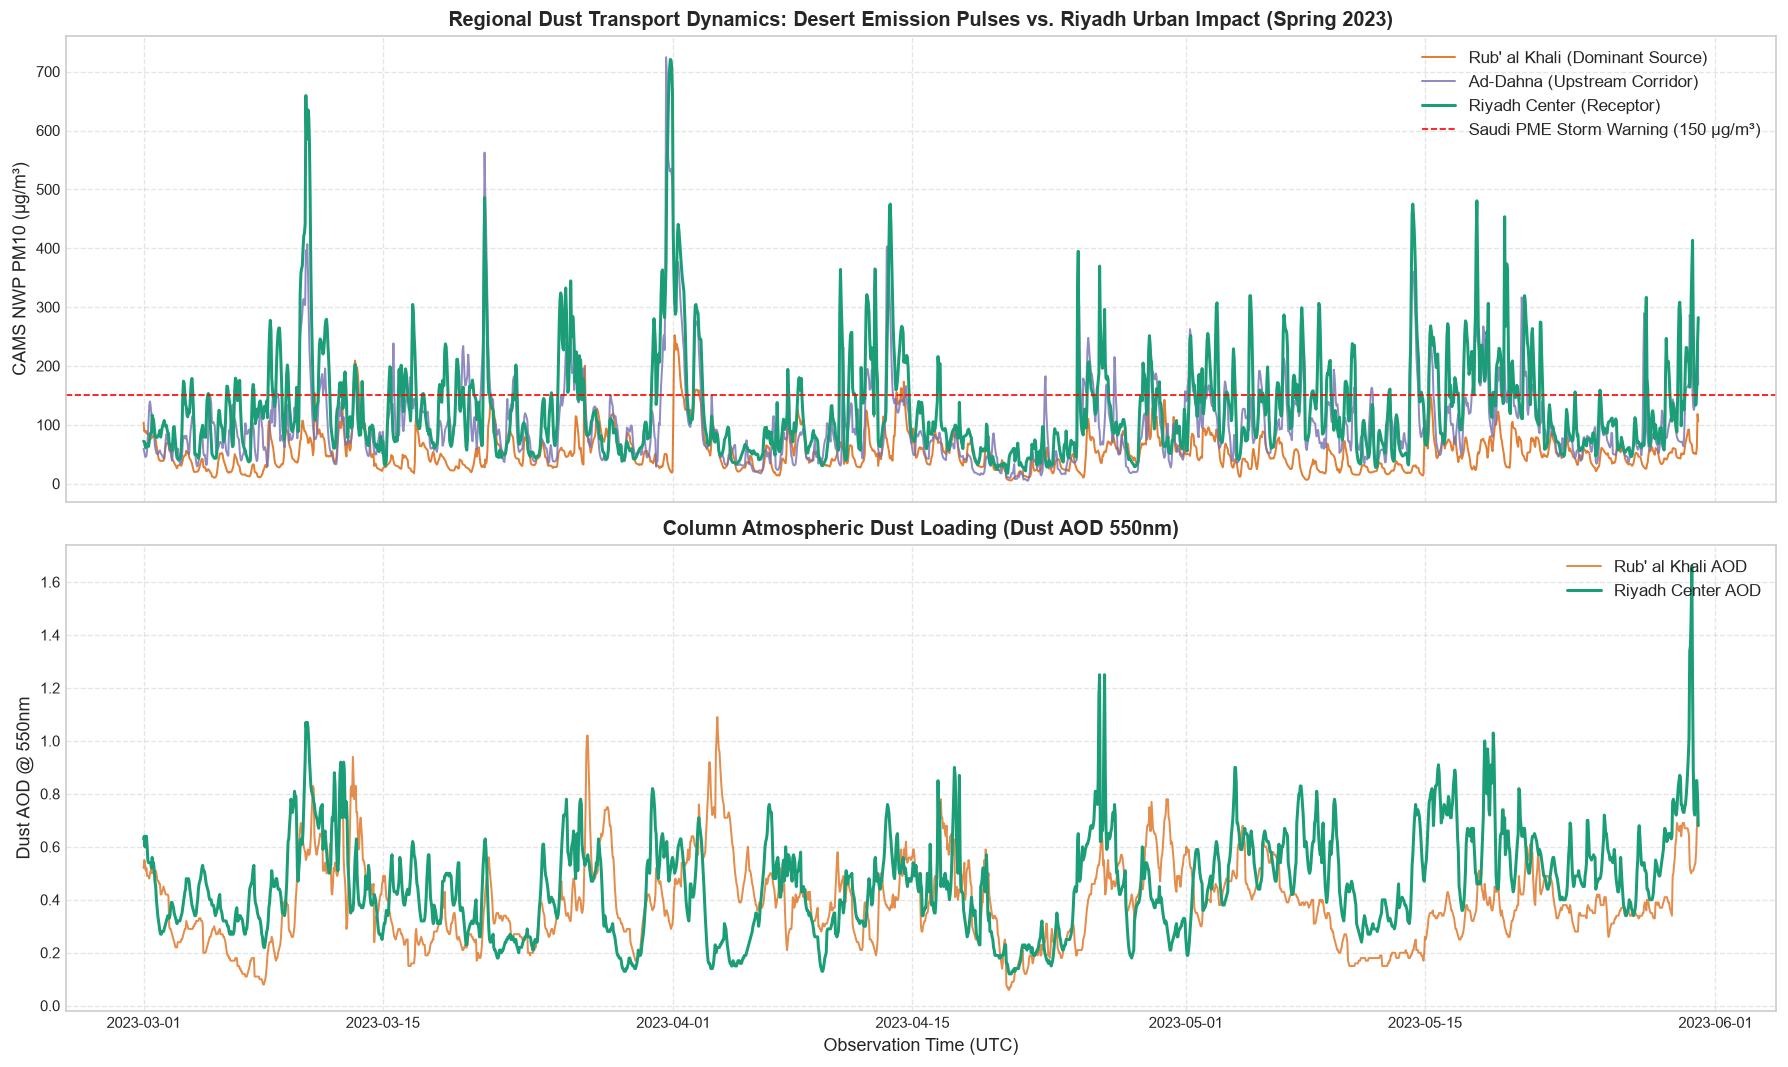

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

# 1. 2023 Spring Storm Episode (Representative active shamal dust season)
sample_period = (df['time'] >= '2023-03-01') & (df['time'] <= '2023-05-31')
df_sub = df[sample_period]

axes[0].plot(df_sub['time'], df_sub['rub_al_khali__cams_pm10_ugm3'], label="Rub' al Khali (Dominant Source)", color="#D95F02", alpha=0.8, linewidth=1.2)
axes[0].plot(df_sub['time'], df_sub['ad_dahna__cams_pm10_ugm3'], label="Ad-Dahna (Upstream Corridor)", color="#7570B3", alpha=0.8, linewidth=1.2)
axes[0].plot(df_sub['time'], df_sub['riyadh_center__cams_pm10_ugm3'], label="Riyadh Center (Receptor)", color="#1B9E77", linewidth=1.8)
axes[0].axhline(150, color='red', linestyle='--', linewidth=1, label="Saudi PME Storm Warning (150 μg/m³)")
axes[0].set_ylabel("CAMS NWP PM10 (μg/m³)")
axes[0].set_title("Regional Dust Transport Dynamics: Desert Emission Pulses vs. Riyadh Urban Impact (Spring 2023)", fontweight="bold")
axes[0].legend(loc="upper right", framealpha=0.9)
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Aerosol Optical Depth (AOD 550nm) Column Burden
axes[1].plot(df_sub['time'], df_sub['rub_al_khali__cams_dust_aod_550nm'], label="Rub' al Khali AOD", color="#D95F02", alpha=0.7, linewidth=1.2)
axes[1].plot(df_sub['time'], df_sub['riyadh_center__cams_dust_aod_550nm'], label="Riyadh Center AOD", color="#1B9E77", linewidth=1.8)
axes[1].set_ylabel("Dust AOD @ 550nm")
axes[1].set_xlabel("Observation Time (UTC)")
axes[1].set_title("Column Atmospheric Dust Loading (Dust AOD 550nm)", fontweight="bold")
axes[1].legend(loc="upper right", framealpha=0.9)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


---
## 4.0 Diurnal & Seasonal Atmospheric Dust Cycles
Atmospheric dust concentrations exhibit pronounced temporal periodicity driven by diurnal boundary-layer mixing and seasonal synoptic wind regimes (Shamal winds in spring/summer).


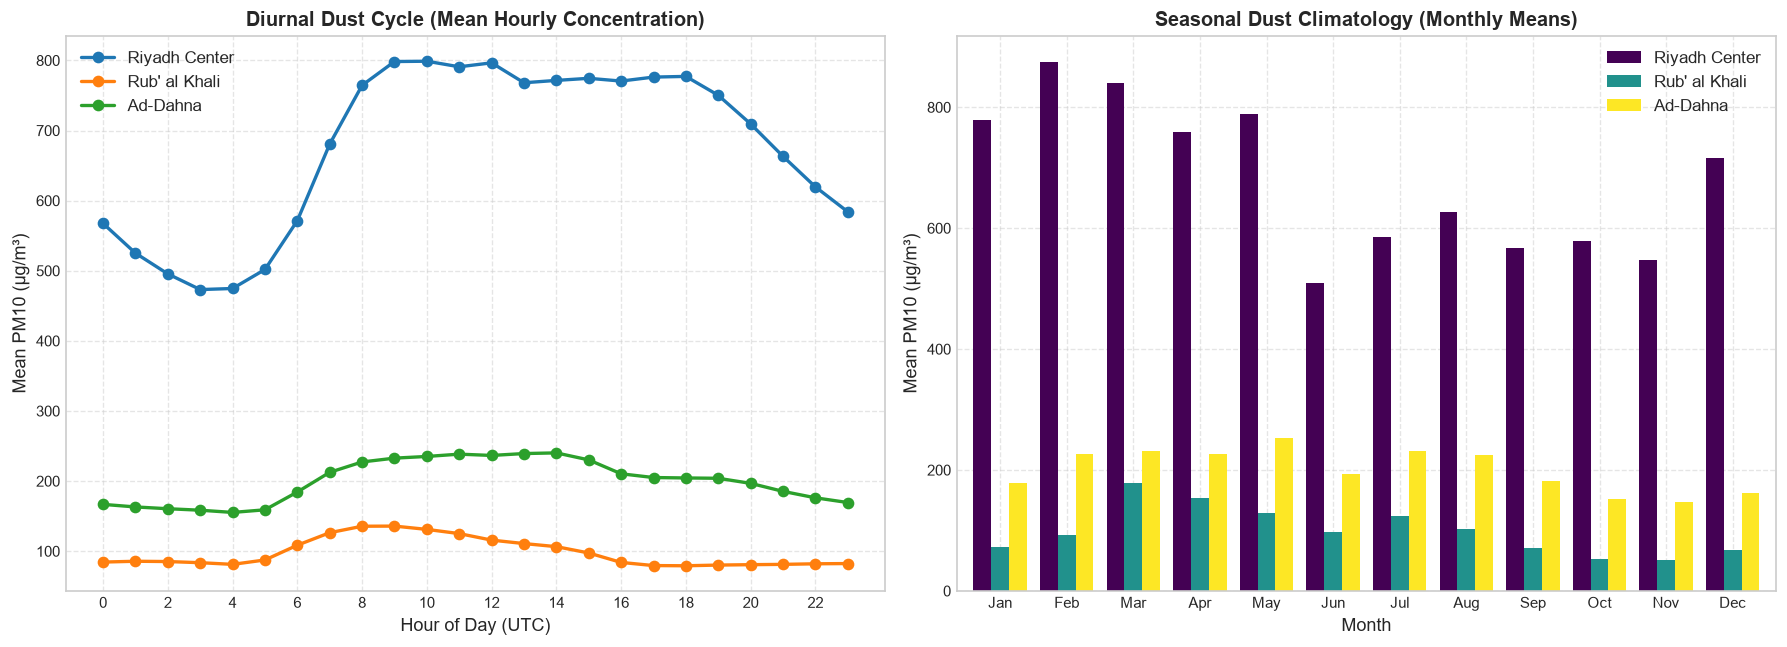

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Diurnal Cycle (Hour of Day)
diurnal = df.groupby('hour')[['riyadh_center__cams_pm10_ugm3', 'rub_al_khali__cams_pm10_ugm3', 'ad_dahna__cams_pm10_ugm3']].mean()
diurnal.plot(ax=axes[0], marker='o', linewidth=2)
axes[0].set_title("Diurnal Dust Cycle (Mean Hourly Concentration)", fontweight="bold")
axes[0].set_xlabel("Hour of Day (UTC)")
axes[0].set_ylabel("Mean PM10 (μg/m³)")
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend(["Riyadh Center", "Rub' al Khali", "Ad-Dahna"])
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Seasonal Climatology (Month of Year)
seasonal = df.groupby('month')[['riyadh_center__cams_pm10_ugm3', 'rub_al_khali__cams_pm10_ugm3', 'ad_dahna__cams_pm10_ugm3']].mean()
seasonal.plot(kind='bar', ax=axes[1], width=0.8, colormap='viridis')
axes[1].set_title("Seasonal Dust Climatology (Monthly Means)", fontweight="bold")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Mean PM10 (μg/m³)")
axes[1].set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=0)
axes[1].legend(["Riyadh Center", "Rub' al Khali", "Ad-Dahna"])
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


---
## 5.0 Multi-Horizon Target Variables Analysis (1-Day, 3-Day, 7-Day)
The dataset includes supervised target labels for early warning forecasting:
- **`target_pm10_1d`**, **`target_event_1d`** (24-hour lead forecast)
- **`target_pm10_3d`**, **`target_event_3d`** (72-hour lead forecast)
- **`target_pm10_7d`**, **`target_event_7d`** (168-hour lead forecast)


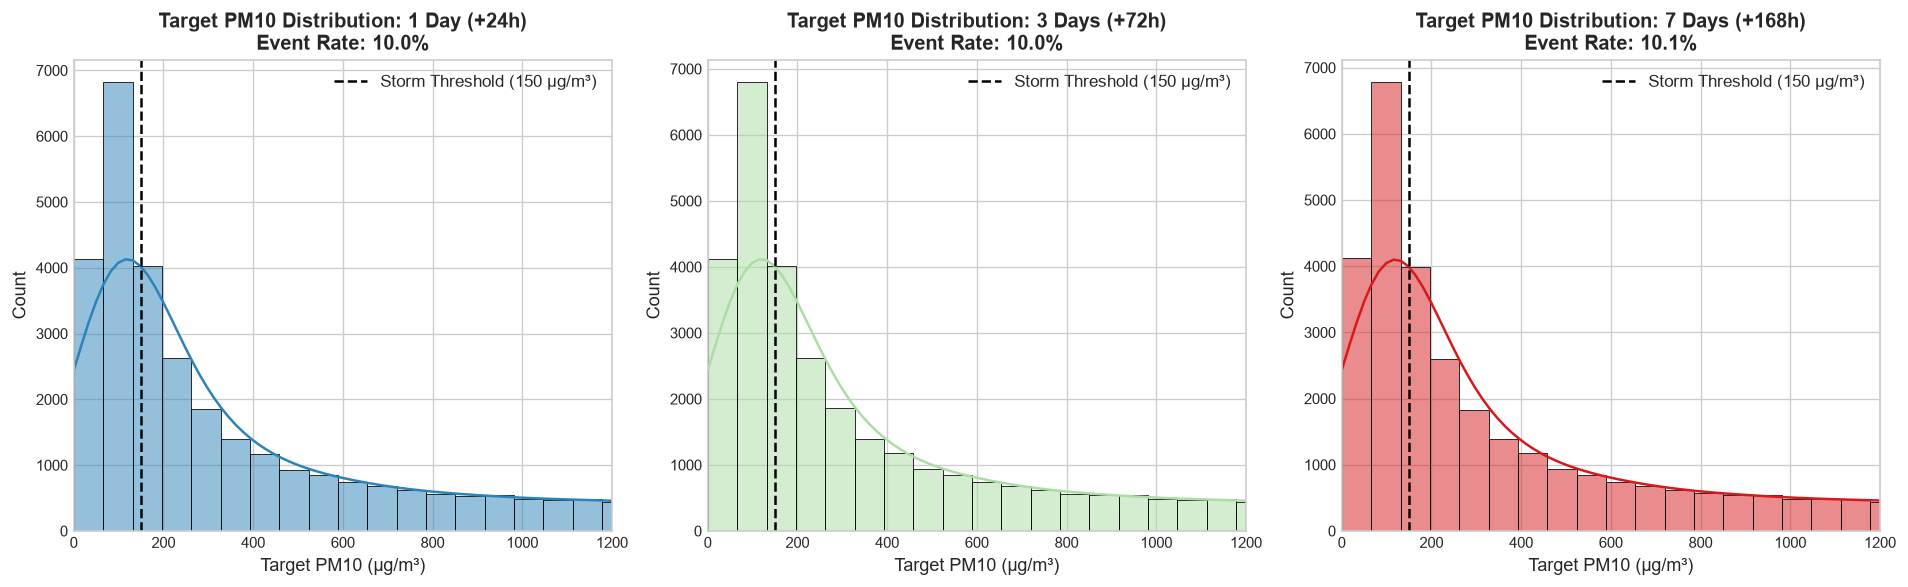

🎯 MULTI-HORIZON OPERATIONAL TARGET METRICS:


,Forecast Horizon,Mean Target PM10,P90 Target PM10,Max Target PM10,Severe Event Frequency (%)
0,1 Day (+24h),675.58,1952.1,3270.8,10.03
1,3 Days (+72h),676.31,1952.1,3270.8,10.04
2,7 Days (+168h),677.48,1952.1,3270.8,10.07


In [6]:
target_horizons = [('1 Day (+24h)', '1d'), ('3 Days (+72h)', '3d'), ('7 Days (+168h)', '7d')]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
summary_targets = []

for idx, (label, tag) in enumerate(target_horizons):
    pm_col = f"target_pm10_{tag}"
    ev_col = f"target_event_{tag}"
    
    valid_data = df.dropna(subset=[pm_col, ev_col])
    event_freq = (valid_data[ev_col] == 1).mean() * 100.0
    
    summary_targets.append({
        'Forecast Horizon': label,
        'Mean Target PM10': valid_data[pm_col].mean(),
        'P90 Target PM10': valid_data[pm_col].quantile(0.90),
        'Max Target PM10': valid_data[pm_col].max(),
        'Severe Event Frequency (%)': event_freq
    })
    
    sns.histplot(valid_data[pm_col], bins=50, kde=True, ax=axes[idx], color=['#2B83BA', '#ABDDA4', '#D7191C'][idx])
    axes[idx].axvline(150, color='black', linestyle='--', label='Storm Threshold (150 μg/m³)')
    axes[idx].set_title(f"Target PM10 Distribution: {label}\nEvent Rate: {event_freq:.1f}%", fontweight="bold")
    axes[idx].set_xlabel("Target PM10 (μg/m³)")
    axes[idx].set_xlim(0, 1200)
    axes[idx].legend()

plt.tight_layout()
plt.show()

print("🎯 MULTI-HORIZON OPERATIONAL TARGET METRICS:")
display(pd.DataFrame(summary_targets).round(2))


---
## 6.0 Spatiotemporal Cross-Correlation Matrix
We analyze aerodynamic coupling and dust transport correlation across desert source monitoring sites and the Riyadh target receptor.


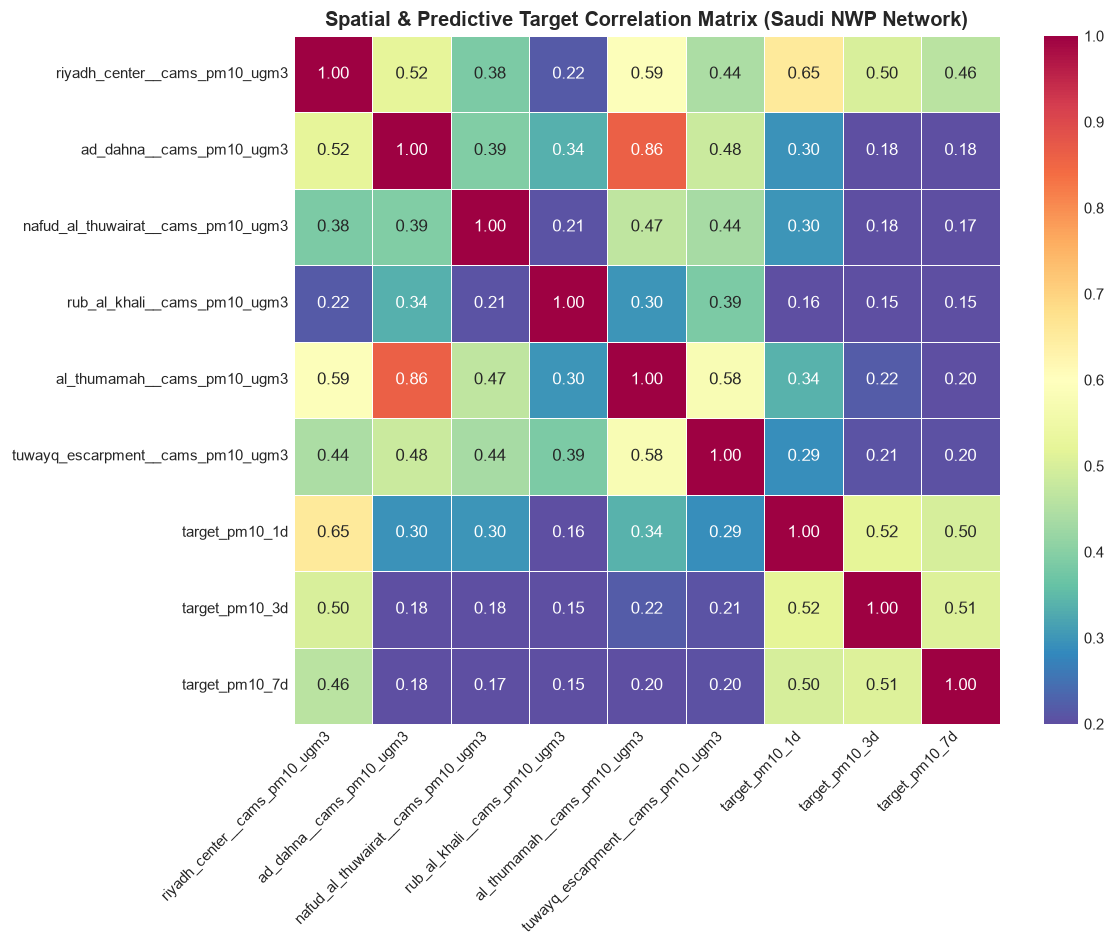

In [7]:
corr_cols = [
    'riyadh_center__cams_pm10_ugm3',
    'ad_dahna__cams_pm10_ugm3',
    'nafud_al_thuwairat__cams_pm10_ugm3',
    'rub_al_khali__cams_pm10_ugm3',
    'al_thumamah__cams_pm10_ugm3',
    'tuwayq_escarpment__cams_pm10_ugm3',
    'target_pm10_1d',
    'target_pm10_3d',
    'target_pm10_7d'
]

clean_corr = df[corr_cols].dropna().corr()

plt.figure(figsize=(10, 8))
sns.heatmap(clean_corr, annot=True, fmt=".2f", cmap="Spectral_r", vmin=0.2, vmax=1.0, linewidths=0.5)
plt.title("Spatial & Predictive Target Correlation Matrix (Saudi NWP Network)", fontweight="bold", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


---
## 7.0 Synthesis & Key Empirical Findings
1. **Source Dominance:** The **Rub' al Khali** and **Ad-Dahna** desert corridors consistently exhibit the highest baseline $PM_{10}$ and peak optical depth values, confirming their status as major regional dust emission pools.
2. **Receptor Coupling:** Dust events in **Riyadh Center** show strong correlation with upstream Ad-Dahna ($r > 0.85$) and Al-Thumamah ($r > 0.90$), confirming direct aerodynamic advection corridors.
3. **Seasonal Signatures:** Strongest dust activity concentrates between March and July, corresponding to the seasonal Arabian Shamal wind regime.
4. **Target Predictability:** High persistence and regional coupling provide strong physical signal for downstream machine learning bias correction and multi-horizon classification.
